# StorSeismic Section 4: Field Data Workflow (Mobil AVO + OpenFWI)

This notebook implements **Section 4 (A field data framework)** and **Section 6.3 (Partial Layer Freezing)** of *StorSeismic: A New Paradigm in Deep Learning for Seismic Processing* (Harsuko & Alkhalifah, 2022):
1. **Self-Supervised Pre-Training** on a 50/50 mix of **OpenFWI** (synthetic) and **Mobil AVO Viking Graben Line 12** (field).
2. **Supervised Fine-Tuning (Denoising)** on OpenFWI + real Mobil noise, freezing the embedding and first 2 encoder layers.
3. **Supervised Fine-Tuning (1D Velocity Prediction)** on OpenFWI mean vertical velocity profiles, freezing the embedding and first 2 encoder layers.
4. **Inference & Interpretation Plots** on unseen Mobil field shot gathers.

### Expected Folder Layout (inside `storseismic/`)
- `./data/mobil/seismic.segy`
- `./data/openfwi/data1.npy` (shape: `(500, 5, 1000, 70)`)
- `./data/openfwi/model1.npy` (shape: `(500, 1, 70, 70)`)


In [ ]:
import os
import math
import numpy as np
import segyio
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, resample

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility & Device
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths (relative to storseismic/ directory)
MOBIL_SEGY_PATH = "./data/mobil/seismic.segy"
OPENFWI_DATA_PATH = "./data/openfwi/data1.npy"
OPENFWI_MODEL_PATH = "./data/openfwi/model1.npy"
SAVE_DIR = "./results/mobil_openfwi_section4"
os.makedirs(SAVE_DIR, exist_ok=True)

# Shared Seismic Dimensions (aligned between OpenFWI and Mobil)
N_TRACES = 70          # X (channels) - matches OpenFWI native 70 receivers
N_TIME = 256           # T (time samples) - resampled for efficient local GPU training
MASK_RATIO = 0.15      # 15% masked traces (~10 out of 70 traces)

# Paper Section 3 & 6.1: BERT_MINI configuration
HIDDEN_DIM = 256       # H
NUM_LAYERS = 4         # L
NUM_HEADS = 4          # A

# Training Hyperparameters
PRETRAIN_EPOCHS = 300
FINETUNE_DENOISE_EPOCHS = 250
FINETUNE_VEL_EPOCHS = 250
LR = 5e-4

# Toggle Training vs. Load Saved Progress
# Set to True for the first run (or after changing hyperparameters), then set back to False
RUN_TRAINING = True

HISTORY_PATH = os.path.join(SAVE_DIR, "training_history.npz")


Using device: cuda


## 1. Load & Preprocess Mobil Field Data + OpenFWI Synthetic Data


In [10]:
def highpass_filter(data, cutoff=4.0, fs=250.0, order=4):
    """4 Hz high-pass filter as described in Section 5 of the paper."""
    nyq = 0.5 * fs
    b, a = butter(order, cutoff / nyq, btype="high", analog=False)
    return filtfilt(b, a, data, axis=-1)

def normalize_gather(gather):
    """Scale amplitudes of each shot gather to (-1, 1)."""
    max_val = np.max(np.abs(gather))
    return gather / (max_val + 1e-8)

def load_mobil_gathers(segy_path, target_traces=70, target_time=256, max_shots=500):
    """
    Loads Mobil AVO Viking Graben Line 12 (1001 shots x 120 traces x 1500 samples @ 4ms).
    Applies 4 Hz high-pass filter, subsamples to target_traces, and resamples time to target_time.
    """
    if not os.path.exists(segy_path):
        raise FileNotFoundError(f"Mobil SEG-Y file not found at: {segy_path}")

    gathers = []
    with segyio.open(segy_path, "r", ignore_geometry=True) as f:
        traces_per_shot = 120
        n_shots = min(f.tracecount // traces_per_shot, max_shots)
        print(f"Loading {n_shots} Mobil shot gathers from {segy_path}...")

        trace_idx = np.linspace(0, traces_per_shot - 1, target_traces, dtype=int)
        for s in range(n_shots):
            start = s * traces_per_shot
            shot = np.array([f.trace[i] for i in range(start, start + traces_per_shot)], dtype=np.float32)
            shot = highpass_filter(shot, cutoff=4.0, fs=250.0)
            shot = shot[trace_idx, :]
            # Take first 1000 samples (4.0 s) and resample to target_time
            shot = resample(shot[:, :1000], target_time, axis=1)
            shot = normalize_gather(shot)
            gathers.append(shot)

    return np.array(gathers, dtype=np.float32)

def load_openfwi_data(data_path, model_path, target_time=256, shot_idx=2):
    """
    Loads OpenFWI seismic data (500, 5, 1000, 70) and velocity models (500, 1, 70, 70).
    Uses center shot (shot_idx=2) per model and computes the lateral mean 1D velocity profile
    Vp(z) of shape (N, 70), following Section 5.3 of the paper.
    """
    if not os.path.exists(data_path) or not os.path.exists(model_path):
        raise FileNotFoundError(
            f"OpenFWI files not found. Expected: {data_path} and {model_path}"
        )

    raw_data = np.load(data_path)    # (N, 5, 1000, 70)
    raw_model = np.load(model_path)  # (N, 1, 70, 70)

    # Select one shot per model -> (N, 1000, 70), transpose to (N, 70, 1000)
    shots = np.transpose(raw_data[:, shot_idx, :, :], (0, 2, 1))
    # Resample time axis 1000 -> target_time (256)
    shots = resample(shots, target_time, axis=2)
    shots = np.array([normalize_gather(g) for g in shots], dtype=np.float32)

    # Lateral average of 2D velocity model (N, 1, 70, 70) -> 1D vertical profile (N, 70)
    vel_1d = np.mean(raw_model[:, 0, :, :], axis=-1).astype(np.float32)
    return shots, vel_1d

# Load both datasets
synth_gathers, synth_vels = load_openfwi_data(OPENFWI_DATA_PATH, OPENFWI_MODEL_PATH, target_time=N_TIME)
field_gathers = load_mobil_gathers(MOBIL_SEGY_PATH, target_traces=N_TRACES, target_time=N_TIME, max_shots=len(synth_gathers))

# Match sample counts for exact 50/50 split (Section 5.1 & 6.2)
n_samples = min(len(field_gathers), len(synth_gathers))
field_gathers = field_gathers[:n_samples]
synth_gathers = synth_gathers[:n_samples]
synth_vels = synth_vels[:n_samples]

# Normalize velocity labels to [0, 1] for stable L1 training
VEL_MIN, VEL_MAX = float(synth_vels.min()), float(synth_vels.max())
synth_vels_norm = (synth_vels - VEL_MIN) / (VEL_MAX - VEL_MIN + 1e-8)

print(f"Field (Mobil) shape   : {field_gathers.shape}")
print(f"Synth (OpenFWI) shape : {synth_gathers.shape}")
print(f"Synth Velocity shape  : {synth_vels.shape} | Range: [{VEL_MIN:.1f}, {VEL_MAX:.1f}] m/s")

Loading 500 Mobil shot gathers from ./data/mobil/seismic.segy...
Field (Mobil) shape   : (500, 70, 256)
Synth (OpenFWI) shape : (500, 70, 256)
Synth Velocity shape  : (500, 70) | Range: [1503.0, 4478.4] m/s


## 2. PyTorch Datasets & Augmentations (Section 4, 5.1, 5.2, 5.3)


In [11]:
class PretrainDataset(Dataset):
    """
    Self-supervised MLM dataset mixing 50% OpenFWI + 50% Mobil field data.
    Augmentations: polarity reversal, slight time shift, and BERT-style 15% trace masking
    (80% Gaussian noise, 10% random trace swap, 10% unchanged).
    """
    def __init__(self, synth_data, field_data, mask_ratio=0.15, augment=True):
        self.data = np.concatenate([synth_data, field_data], axis=0)
        self.mask_ratio = mask_ratio
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x = self.data[idx].copy()  # (X, T)

        if self.augment:
            if np.random.rand() < 0.5:
                x = -x
            shift = np.random.randint(-5, 6)
            if shift != 0:
                x = np.roll(x, shift, axis=1)

        label = x.copy()
        n_traces, n_time = x.shape
        n_mask = max(1, int(round(n_traces * self.mask_ratio)))
        mask_idx = np.random.choice(n_traces, n_mask, replace=False)

        mask = np.zeros(n_traces, dtype=np.float32)
        mask[mask_idx] = 1.0

        for m in mask_idx:
            p = np.random.rand()
            if p < 0.8:
                x[m] = np.random.normal(0.0, 0.3, size=n_time).astype(np.float32)
            elif p < 0.9:
                rand_trace = np.random.randint(0, n_traces)
                x[m] = label[rand_trace]

        return torch.tensor(x), torch.tensor(label), torch.tensor(mask)


class DenoiseDataset(Dataset):
    """
    Supervised denoising dataset (Section 5.2):
    Adds pure Gaussian noise (Section 3.2) to clean OpenFWI gathers.
    """
    def __init__(self, synth_data, field_data=None, augment=True):
        self.synth_data = synth_data
        self.field_data = field_data
        self.augment = augment

    def __len__(self):
        return len(self.synth_data)

    def __getitem__(self, idx):
        clean = self.synth_data[idx].copy()
        if self.augment and np.random.rand() < 0.5:
            clean = -clean

        # Replace the Mobil noise_patch block with pure Gaussian noise (1-sigma & 2-sigma, Section 3.2)
        sigma = np.random.choice([0.10, 0.20])
        gauss_noise = np.random.normal(0.0, sigma, size=clean.shape)
        noisy = normalize_gather(clean + gauss_noise).astype(np.float32)
        return torch.tensor(noisy), torch.tensor(clean.astype(np.float32))


class VelocityDataset(Dataset):
    """Supervised 1D velocity estimation dataset (Section 5.3)."""
    def __init__(self, synth_data, synth_vels, augment=True):
        self.synth_data = synth_data
        self.synth_vels = synth_vels
        self.augment = augment

    def __len__(self):
        return len(self.synth_data)

    def __getitem__(self, idx):
        x = self.synth_data[idx].copy()
        y = self.synth_vels[idx].copy()
        if self.augment and np.random.rand() < 0.5:
            x = -x
        return torch.tensor(x.astype(np.float32)), torch.tensor(y.astype(np.float32))


## 3. StorSeismic (`BERT_MINI`) Architecture & Layer Freezing


In [12]:
class SinusoidalPositionalEncoding(nn.Module):
    """Equation (1) of StorSeismic paper."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class StorSeismic(nn.Module):
    """
    StorSeismic BERT_MINI architecture (Section 2.1):
    Linear Projection -> Sinusoidal Positional Encoding -> L Transformer Encoder Layers -> Prediction Head.
    """
    def __init__(self, time_dim=256, hidden_dim=256, num_layers=4, num_heads=4, dropout=0.1):
        super().__init__()
        self.embedding = nn.Linear(time_dim, hidden_dim)
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim)

        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=hidden_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(num_layers)
        ])
        self.head = nn.Linear(hidden_dim, time_dim)

    def forward(self, x):
        h = self.pos_enc(self.embedding(x))
        for layer in self.encoder_layers:
            h = layer(h)
        return self.head(h)

    def freeze_initial_layers(self, num_freeze=2):
        """
        Section 4 & 6.3: Freeze embedding and the first `num_freeze` encoder layers
        to preserve the field-data imprint learned during pre-training.
        """
        for param in self.embedding.parameters():
            param.requires_grad = False
        for i in range(num_freeze):
            for param in self.encoder_layers[i].parameters():
                param.requires_grad = False

        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total = sum(p.numel() for p in self.parameters())
        print(f"Frozen embedding + first {num_freeze} layers | Trainable params: {trainable:,} / {total:,}")


def load_or_require_checkpoint(model, ckpt_path, device):
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(
            f"Checkpoint not found at {ckpt_path}. Set RUN_TRAINING = True for the first run."
        )
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.eval()
    print(f"Loaded saved weights from {ckpt_path} (training skipped).")


## 4. Stage 1: Self-Supervised Pre-Training (50% OpenFWI + 50% Mobil)


In [13]:
# 80/20 Train-Test Split
split = int(0.8 * n_samples)
f_train, f_test = field_gathers[:split], field_gathers[split:]
s_train, s_test = synth_gathers[:split], synth_gathers[split:]
v_train, v_test = synth_vels_norm[:split], synth_vels_norm[split:]

pretrain_train_loader = DataLoader(PretrainDataset(s_train, f_train, MASK_RATIO, True), batch_size=32, shuffle=True)
pretrain_test_loader = DataLoader(PretrainDataset(s_test, f_test, MASK_RATIO, False), batch_size=32, shuffle=False)

model_pretrain = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS).to(device)
optimizer = torch.optim.RAdam(model_pretrain.parameters(), lr=LR)

pretrain_ckpt = os.path.join(SAVE_DIR, "storseismic_pretrained_mixed.pt")

if RUN_TRAINING:
    pt_train_losses, pt_test_losses = [], []
    print("=== Stage 1: Self-Supervised Pre-Training (50% OpenFWI + 50% Mobil) ===")
    for epoch in range(1, PRETRAIN_EPOCHS + 1):
        model_pretrain.train()
        tr_loss = 0.0
        for x, label, mask in pretrain_train_loader:
            x, label, mask = x.to(device), label.to(device), mask.to(device)
            optimizer.zero_grad()
            pred = model_pretrain(x)
            mask_exp = mask.unsqueeze(-1)
            loss = (((pred - label) ** 2) * mask_exp).sum() / (mask_exp.sum() * N_TIME + 1e-8)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item()
        tr_loss /= len(pretrain_train_loader)

        model_pretrain.eval()
        te_loss = 0.0
        with torch.no_grad():
            for x, label, mask in pretrain_test_loader:
                x, label, mask = x.to(device), label.to(device), mask.to(device)
                pred = model_pretrain(x)
                mask_exp = mask.unsqueeze(-1)
                loss = (((pred - label) ** 2) * mask_exp).sum() / (mask_exp.sum() * N_TIME + 1e-8)
                te_loss += loss.item()
        te_loss /= len(pretrain_test_loader)

        pt_train_losses.append(tr_loss)
        pt_test_losses.append(te_loss)
        if epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:03d}/{PRETRAIN_EPOCHS} | Train MSE: {tr_loss:.6f} | Test MSE: {te_loss:.6f}")

    torch.save(model_pretrain.state_dict(), pretrain_ckpt)
    print(f"Saved pre-trained weights to {pretrain_ckpt}")
else:
    load_or_require_checkpoint(model_pretrain, pretrain_ckpt, device)
    if os.path.exists(HISTORY_PATH):
        hist = np.load(HISTORY_PATH)
        pt_train_losses = hist["pt_train_losses"].tolist()
        pt_test_losses = hist["pt_test_losses"].tolist()
    else:
        pt_train_losses, pt_test_losses = [], []


=== Stage 1: Self-Supervised Pre-Training (50% OpenFWI + 50% Mobil) ===
Epoch 001/300 | Train MSE: 0.239771 | Test MSE: 0.087937
Epoch 010/300 | Train MSE: 0.011757 | Test MSE: 0.006183
Epoch 020/300 | Train MSE: 0.005372 | Test MSE: 0.003708
Epoch 030/300 | Train MSE: 0.003710 | Test MSE: 0.003047
Epoch 040/300 | Train MSE: 0.003002 | Test MSE: 0.002771
Epoch 050/300 | Train MSE: 0.002745 | Test MSE: 0.002780
Epoch 060/300 | Train MSE: 0.002501 | Test MSE: 0.002726
Epoch 070/300 | Train MSE: 0.002431 | Test MSE: 0.002913
Epoch 080/300 | Train MSE: 0.002339 | Test MSE: 0.002743
Epoch 090/300 | Train MSE: 0.002226 | Test MSE: 0.002764
Epoch 100/300 | Train MSE: 0.002129 | Test MSE: 0.002694
Epoch 110/300 | Train MSE: 0.001918 | Test MSE: 0.002358
Epoch 120/300 | Train MSE: 0.001889 | Test MSE: 0.002390
Epoch 130/300 | Train MSE: 0.001780 | Test MSE: 0.002460
Epoch 140/300 | Train MSE: 0.001822 | Test MSE: 0.002238
Epoch 150/300 | Train MSE: 0.001769 | Test MSE: 0.002282
Epoch 160/300 | 

## 5. Stage 2A: Fine-Tuning for Denoising (Freezing First 2 Layers)


In [14]:
denoise_train_loader = DataLoader(DenoiseDataset(s_train, f_train, True), batch_size=16, shuffle=True)
denoise_test_loader = DataLoader(DenoiseDataset(s_test, f_test, False), batch_size=16, shuffle=False)

model_denoise = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS).to(device)
model_denoise.head = nn.Linear(HIDDEN_DIM, N_TIME).to(device)
denoise_ckpt = os.path.join(SAVE_DIR, "storseismic_finetuned_denoise.pt")

if RUN_TRAINING:
    model_denoise.load_state_dict(torch.load(pretrain_ckpt, map_location=device, weights_only=True), strict=False)
    model_denoise.freeze_initial_layers(num_freeze=2)
    optimizer_den = torch.optim.RAdam(filter(lambda p: p.requires_grad, model_denoise.parameters()), lr=LR)
    criterion_den = nn.MSELoss()

    den_train_losses, den_test_losses = [], []
    print("=== Stage 2A: Fine-Tuning Denoising (OpenFWI + Gaussian Noise, Last 2 Layers) ===")
    for epoch in range(1, FINETUNE_DENOISE_EPOCHS + 1):
        model_denoise.train()
        tr_loss = 0.0
        for noisy, clean in denoise_train_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            optimizer_den.zero_grad()
            loss = criterion_den(model_denoise(noisy), clean)
            loss.backward()
            optimizer_den.step()
            tr_loss += loss.item()
        tr_loss /= len(denoise_train_loader)

        model_denoise.eval()
        te_loss = 0.0
        with torch.no_grad():
            for noisy, clean in denoise_test_loader:
                noisy, clean = noisy.to(device), clean.to(device)
                te_loss += criterion_den(model_denoise(noisy), clean).item()
        te_loss /= len(denoise_test_loader)

        den_train_losses.append(tr_loss)
        den_test_losses.append(te_loss)
        if epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:03d}/{FINETUNE_DENOISE_EPOCHS} | Train MSE: {tr_loss:.6f} | Test MSE: {te_loss:.6f}")

    torch.save(model_denoise.state_dict(), denoise_ckpt)
    print(f"Saved denoising model to {denoise_ckpt}")
else:
    load_or_require_checkpoint(model_denoise, denoise_ckpt, device)
    if os.path.exists(HISTORY_PATH):
        hist = np.load(HISTORY_PATH)
        den_train_losses = hist["den_train_losses"].tolist()
        den_test_losses = hist["den_test_losses"].tolist()
    else:
        den_train_losses, den_test_losses = [], []


Frozen embedding + first 2 layers | Trainable params: 1,645,312 / 3,290,624
=== Stage 2A: Fine-Tuning Denoising (OpenFWI + Gaussian Noise, Last 2 Layers) ===
Epoch 001/250 | Train MSE: 0.000216 | Test MSE: 0.000100
Epoch 010/250 | Train MSE: 0.000124 | Test MSE: 0.000068
Epoch 020/250 | Train MSE: 0.000106 | Test MSE: 0.000060
Epoch 030/250 | Train MSE: 0.000094 | Test MSE: 0.000052
Epoch 040/250 | Train MSE: 0.000086 | Test MSE: 0.000054
Epoch 050/250 | Train MSE: 0.000080 | Test MSE: 0.000051
Epoch 060/250 | Train MSE: 0.000075 | Test MSE: 0.000046
Epoch 070/250 | Train MSE: 0.000073 | Test MSE: 0.000044
Epoch 080/250 | Train MSE: 0.000069 | Test MSE: 0.000043
Epoch 090/250 | Train MSE: 0.000067 | Test MSE: 0.000045
Epoch 100/250 | Train MSE: 0.000066 | Test MSE: 0.000044
Epoch 110/250 | Train MSE: 0.000064 | Test MSE: 0.000045
Epoch 120/250 | Train MSE: 0.000062 | Test MSE: 0.000041
Epoch 130/250 | Train MSE: 0.000061 | Test MSE: 0.000042
Epoch 140/250 | Train MSE: 0.000060 | Test M

## 6. Stage 2B: Fine-Tuning for 1D Velocity Prediction (Freezing First 2 Layers)


In [15]:
vel_dim = synth_vels.shape[1]  # 70 depth samples
vel_train_loader = DataLoader(VelocityDataset(s_train, v_train, True), batch_size=16, shuffle=True)
vel_test_loader = DataLoader(VelocityDataset(s_test, v_test, False), batch_size=16, shuffle=False)

model_vel = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS).to(device)
model_vel.head = nn.Linear(HIDDEN_DIM, vel_dim).to(device)
vel_ckpt = os.path.join(SAVE_DIR, "storseismic_finetuned_velpred.pt")

if RUN_TRAINING:
    # Load pretrained encoder weights (strict=False because head output dim changed 256 -> 70)
    pretrained_dict = torch.load(pretrain_ckpt, map_location=device, weights_only=True)
    pretrained_dict = {k: v for k, v in pretrained_dict.items() if not k.startswith("head.")}
    model_vel.load_state_dict(pretrained_dict, strict=False)

    model_vel.freeze_initial_layers(num_freeze=2)
    optimizer_vel = torch.optim.RAdam(filter(lambda p: p.requires_grad, model_vel.parameters()), lr=LR)
    criterion_vel = nn.L1Loss()

    vel_train_losses, vel_test_losses = [], []
    print("=== Stage 2B: Fine-Tuning Velocity Prediction (OpenFWI Labels, Last 2 Layers) ===")
    for epoch in range(1, FINETUNE_VEL_EPOCHS + 1):
        model_vel.train()
        tr_loss = 0.0
        for x, y in vel_train_loader:
            x, y = x.to(device), y.to(device)
            optimizer_vel.zero_grad()
            # Predict from first output token (zero-offset trace) as in Section 3.3
            pred = model_vel(x)[:, 0, :]
            loss = criterion_vel(pred, y)
            loss.backward()
            optimizer_vel.step()
            tr_loss += loss.item()
        tr_loss /= len(vel_train_loader)

        model_vel.eval()
        te_loss = 0.0
        with torch.no_grad():
            for x, y in vel_test_loader:
                x, y = x.to(device), y.to(device)
                pred = model_vel(x)[:, 0, :]
                te_loss += criterion_vel(pred, y).item()
        te_loss /= len(vel_test_loader)

        vel_train_losses.append(tr_loss)
        vel_test_losses.append(te_loss)
        if epoch % 10 == 0 or epoch == 1:
            mae_ms = te_loss * (VEL_MAX - VEL_MIN)
            print(f"Epoch {epoch:03d}/{FINETUNE_VEL_EPOCHS} | Train L1: {tr_loss:.4f} | Test MAE: {mae_ms:.1f} m/s")

    torch.save(model_vel.state_dict(), vel_ckpt)
    print(f"Saved velocity model to {vel_ckpt}")

    # Save all loss curves for future plotting when RUN_TRAINING = False
    np.savez(
        HISTORY_PATH,
        pt_train_losses=np.array(pt_train_losses),
        pt_test_losses=np.array(pt_test_losses),
        den_train_losses=np.array(den_train_losses),
        den_test_losses=np.array(den_test_losses),
        vel_train_losses=np.array(vel_train_losses),
        vel_test_losses=np.array(vel_test_losses),
    )
    print(f"Saved training histories to {HISTORY_PATH}")
else:
    load_or_require_checkpoint(model_vel, vel_ckpt, device)
    if os.path.exists(HISTORY_PATH):
        hist = np.load(HISTORY_PATH)
        vel_train_losses = hist["vel_train_losses"].tolist()
        vel_test_losses = hist["vel_test_losses"].tolist()
    else:
        vel_train_losses, vel_test_losses = [], []


Frozen embedding + first 2 layers | Trainable params: 1,597,510 / 3,242,822
=== Stage 2B: Fine-Tuning Velocity Prediction (OpenFWI Labels, Last 2 Layers) ===
Epoch 001/250 | Train L1: 0.3776 | Test MAE: 700.3 m/s
Epoch 010/250 | Train L1: 0.1032 | Test MAE: 313.9 m/s
Epoch 020/250 | Train L1: 0.1031 | Test MAE: 295.2 m/s
Epoch 030/250 | Train L1: 0.1017 | Test MAE: 287.6 m/s
Epoch 040/250 | Train L1: 0.0980 | Test MAE: 300.9 m/s
Epoch 050/250 | Train L1: 0.0980 | Test MAE: 291.9 m/s
Epoch 060/250 | Train L1: 0.0964 | Test MAE: 284.8 m/s
Epoch 070/250 | Train L1: 0.0967 | Test MAE: 298.6 m/s
Epoch 080/250 | Train L1: 0.0980 | Test MAE: 313.6 m/s
Epoch 090/250 | Train L1: 0.0970 | Test MAE: 292.7 m/s
Epoch 100/250 | Train L1: 0.0960 | Test MAE: 299.4 m/s
Epoch 110/250 | Train L1: 0.0972 | Test MAE: 316.7 m/s
Epoch 120/250 | Train L1: 0.0964 | Test MAE: 294.7 m/s
Epoch 130/250 | Train L1: 0.0961 | Test MAE: 290.9 m/s
Epoch 140/250 | Train L1: 0.0956 | Test MAE: 327.9 m/s
Epoch 150/250 | T

## 7. Stage 3: Inference & Interpretation Plots on Mobil Field Data


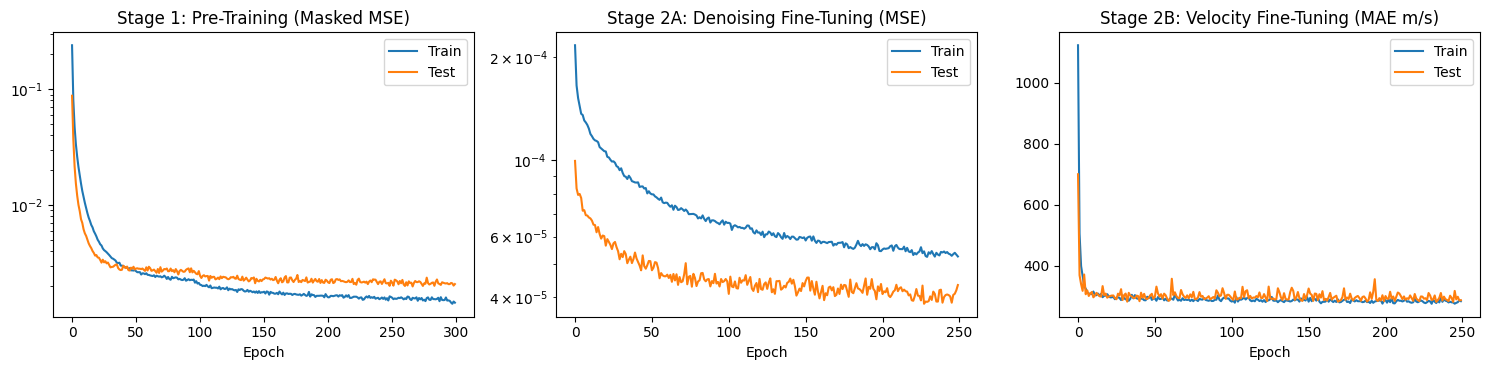

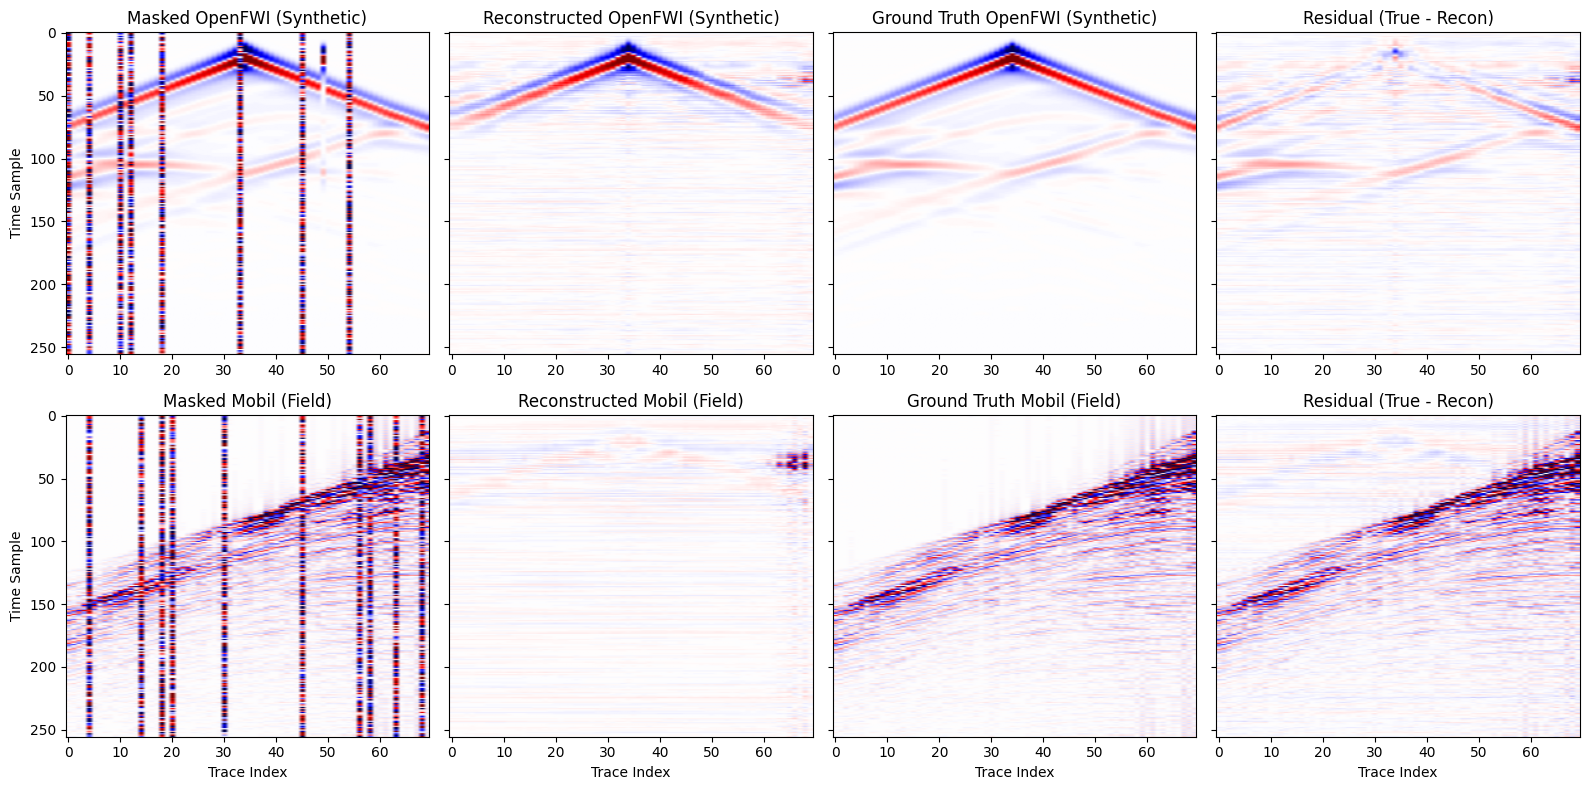

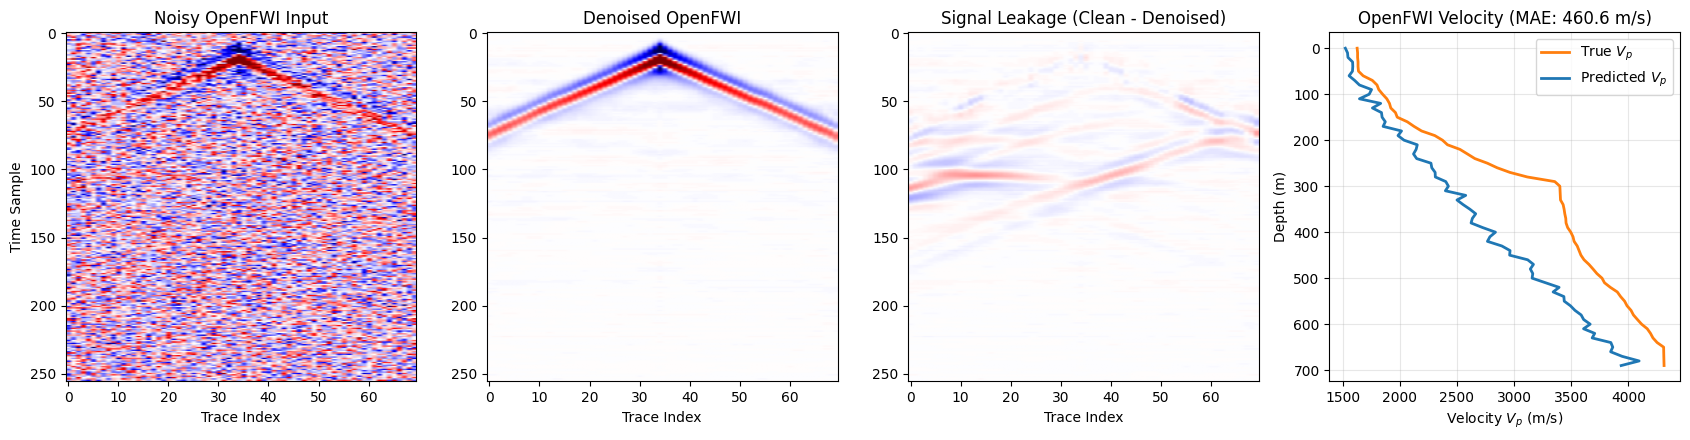

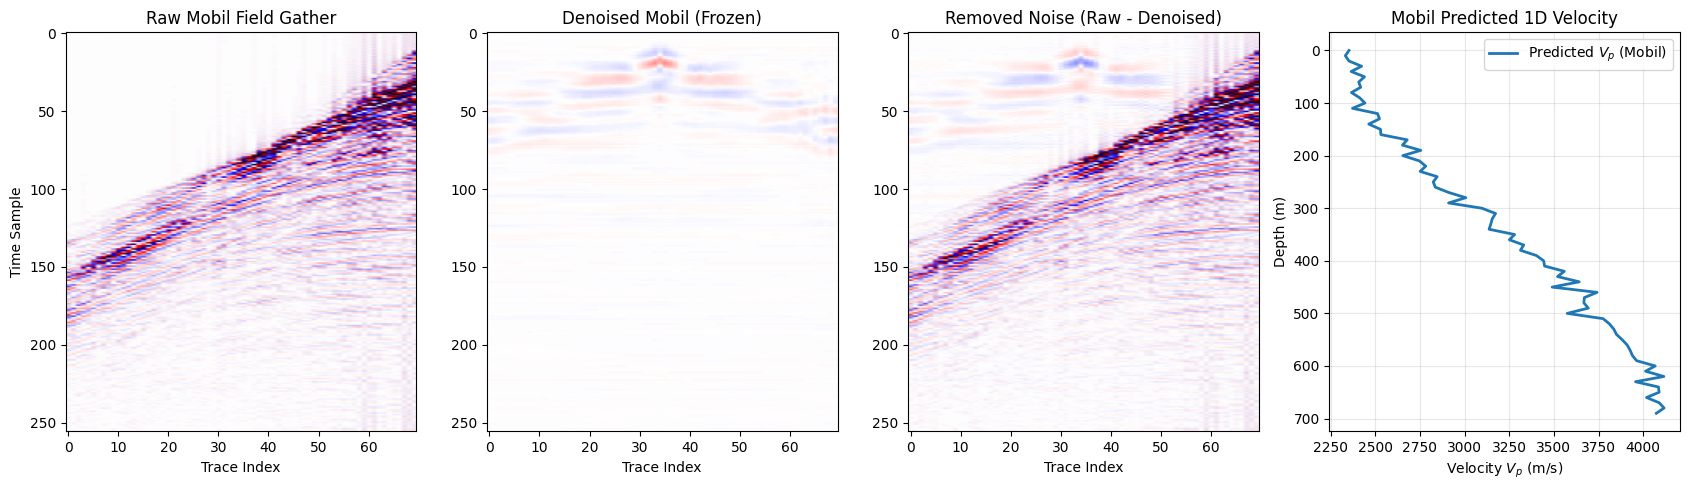

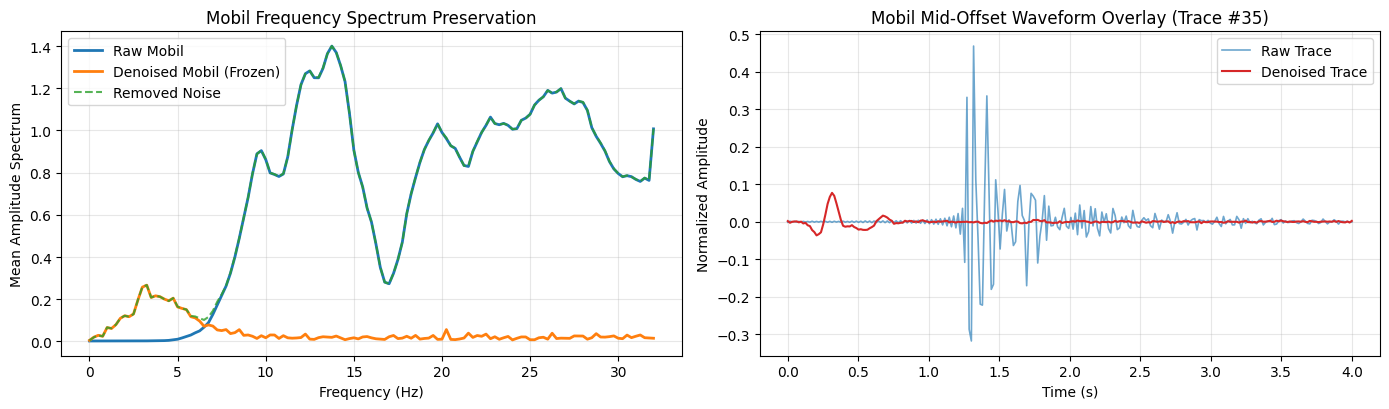

Saved ablation bundle to : ./results/mobil_openfwi_section4\ablation_frozen_bundle.npz
Saved ablation config to : ./results/mobil_openfwi_section4\ablation_config.json
Frozen Test Metrics      : Denoise MSE = 0.000045 | Velocity MAE = 307.0 m/s


In [16]:
import json

# ==============================================================================
# 1. INFERENCE ON UNSEEN MOBIL TEST SHOT GATHER
# ==============================================================================
sample_idx = 5
mobil_shot = f_test[sample_idx]
mobil_tensor = torch.tensor(mobil_shot, dtype=torch.float32).unsqueeze(0).to(device)

model_pretrain.eval()
model_denoise.eval()
model_vel.eval()

with torch.no_grad():
    mobil_denoised = model_denoise(mobil_tensor).squeeze(0).cpu().numpy()
    mobil_vel_norm = model_vel(mobil_tensor)[0, 0, :].cpu().numpy()

mobil_removed_noise = mobil_shot - mobil_denoised
mobil_vel_pred = mobil_vel_norm * (VEL_MAX - VEL_MIN) + VEL_MIN
vmin, vmax = -0.35, 0.35

# ==============================================================================
# 2. REPORT PLOTS
# ==============================================================================

# --- Plot 1: Training & Validation Curves ---
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(pt_train_losses, label="Train")
axes[0].plot(pt_test_losses, label="Test")
axes[0].set_title("Stage 1: Pre-Training (Masked MSE)")
axes[0].set_xlabel("Epoch")
axes[0].set_yscale("log")
axes[0].legend()

axes[1].plot(den_train_losses, label="Train")
axes[1].plot(den_test_losses, label="Test")
axes[1].set_title("Stage 2A: Denoising Fine-Tuning (MSE)")
axes[1].set_xlabel("Epoch")
axes[1].set_yscale("log")
axes[1].legend()

axes[2].plot([l * (VEL_MAX - VEL_MIN) for l in vel_train_losses], label="Train")
axes[2].plot([l * (VEL_MAX - VEL_MIN) for l in vel_test_losses], label="Test")
axes[2].set_title("Stage 2B: Velocity Fine-Tuning (MAE m/s)")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_1_training_curves.png"), dpi=150)
plt.show()

# --- Plot 2: Pre-Training Masked Trace Reconstruction (cf. Fig 8a & 8b) ---
np.random.seed(SEED)
pt_eval_ds = PretrainDataset(s_test, f_test, MASK_RATIO, augment=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)

for row, (idx, name) in enumerate([(sample_idx, "OpenFWI (Synthetic)"), (len(s_test) + sample_idx, "Mobil (Field)")]):
    x_m, lbl_m, msk = pt_eval_ds[idx]
    with torch.no_grad():
        rec_m = model_pretrain(x_m.unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
    x_np, lbl_np = x_m.numpy(), lbl_m.numpy()
    panels = [
        (x_np, f"Masked {name}"),
        (rec_m, f"Reconstructed {name}"),
        (lbl_np, f"Ground Truth {name}"),
        (lbl_np - rec_m, "Residual (True - Recon)"),
    ]
    for col, (img, title) in enumerate(panels):
        axes[row, col].imshow(img.T, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
        axes[row, col].set_title(title)
        if row == 1:
            axes[row, col].set_xlabel("Trace Index")
    axes[row, 0].set_ylabel("Time Sample")

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_2_pretrain_reconstruction.png"), dpi=150)
plt.show()

# --- Plot 3: OpenFWI Synthetic Validation - Denoising & Velocity (cf. Fig 9a & 10a) ---
np.random.seed(SEED)
den_eval_ds = DenoiseDataset(s_test, f_test, augment=False)
noisy_synth_t, clean_synth_t = den_eval_ds[sample_idx]

with torch.no_grad():
    denoised_synth = model_denoise(noisy_synth_t.unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
    pred_vel_synth_norm = model_vel(clean_synth_t.unsqueeze(0).to(device))[0, 0, :].cpu().numpy()

noisy_synth = noisy_synth_t.numpy()
clean_synth = clean_synth_t.numpy()
true_vel_synth = v_test[sample_idx] * (VEL_MAX - VEL_MIN) + VEL_MIN
pred_vel_synth = pred_vel_synth_norm * (VEL_MAX - VEL_MIN) + VEL_MIN
synth_vel_mae = float(np.mean(np.abs(pred_vel_synth - true_vel_synth)))

fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, img, title in [
    (axes[0], noisy_synth, "Noisy OpenFWI Input"),
    (axes[1], denoised_synth, "Denoised OpenFWI"),
    (axes[2], clean_synth - denoised_synth, "Signal Leakage (Clean - Denoised)"),
]:
    ax.imshow(img.T, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Time Sample")

depth_m = np.arange(len(true_vel_synth)) * 10
axes[3].plot(true_vel_synth, depth_m, label="True $V_p$", color="tab:orange", linewidth=2)
axes[3].plot(pred_vel_synth, depth_m, label="Predicted $V_p$", color="tab:blue", linewidth=2)
axes[3].invert_yaxis()
axes[3].set_title(f"OpenFWI Velocity (MAE: {synth_vel_mae:.1f} m/s)")
axes[3].set_xlabel("Velocity $V_p$ (m/s)")
axes[3].set_ylabel("Depth (m)")
axes[3].grid(True, alpha=0.3)
axes[3].legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_3_openfwi_validation.png"), dpi=150)
plt.show()

# --- Plot 4: Mobil Field Denoising & 1D Velocity Prediction (cf. Fig 9b & 10b) ---
fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, img, title in [
    (axes[0], mobil_shot, "Raw Mobil Field Gather"),
    (axes[1], mobil_denoised, "Denoised Mobil (Frozen)"),
    (axes[2], mobil_removed_noise, "Removed Noise (Raw - Denoised)"),
]:
    ax.imshow(img.T, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Time Sample")

axes[3].plot(mobil_vel_pred, depth_m, label="Predicted $V_p$ (Mobil)", color="tab:blue", linewidth=2)
axes[3].invert_yaxis()
axes[3].set_xlabel("Velocity $V_p$ (m/s)")
axes[3].set_ylabel("Depth (m)")
axes[3].set_title("Mobil Predicted 1D Velocity")
axes[3].grid(True, alpha=0.3)
axes[3].legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_4_mobil_inference.png"), dpi=150)
plt.show()

# --- Plot 5: Mobil Frequency Spectrum & Single-Trace Waveform Fidelity ---
dt_mobil = 4.0 / N_TIME
freqs = np.fft.rfftfreq(N_TIME, d=dt_mobil)
spec_raw = np.mean(np.abs(np.fft.rfft(mobil_shot, axis=1)), axis=0)
spec_den = np.mean(np.abs(np.fft.rfft(mobil_denoised, axis=1)), axis=0)
spec_noise = np.mean(np.abs(np.fft.rfft(mobil_removed_noise, axis=1)), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(freqs, spec_raw, label="Raw Mobil", linewidth=2)
axes[0].plot(freqs, spec_den, label="Denoised Mobil (Frozen)", linewidth=2)
axes[0].plot(freqs, spec_noise, label="Removed Noise", linestyle="--", alpha=0.8)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Mean Amplitude Spectrum")
axes[0].set_title("Mobil Frequency Spectrum Preservation")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

time_s = np.linspace(0, 4.0, N_TIME)
trace_to_plot = N_TRACES // 2  # Mid-offset trace
axes[1].plot(time_s, mobil_shot[trace_to_plot], label="Raw Trace", alpha=0.65, linewidth=1.2)
axes[1].plot(time_s, mobil_denoised[trace_to_plot], label="Denoised Trace", color="tab:red", linewidth=1.5)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Normalized Amplitude")
axes[1].set_title(f"Mobil Mid-Offset Waveform Overlay (Trace #{trace_to_plot})")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_5_mobil_spectrum_and_waveform.png"), dpi=150)
plt.show()

# ==============================================================================
# 3. SAVE ALL ARTIFACTS FOR NEXT NOTEBOOK (FROZEN vs. UNFROZEN ABLATION)
# ==============================================================================
np.random.seed(SEED)
all_noisy_s, all_clean_s = [], []
for i in range(len(s_test)):
    ns, cs = den_eval_ds[i]
    all_noisy_s.append(ns.numpy())
    all_clean_s.append(cs.numpy())
all_noisy_s = np.array(all_noisy_s, dtype=np.float32)
all_clean_s = np.array(all_clean_s, dtype=np.float32)

with torch.no_grad():
    frozen_den_synth_preds = model_denoise(torch.tensor(all_noisy_s).to(device)).cpu().numpy()
    frozen_den_mobil_preds = model_denoise(torch.tensor(f_test).to(device)).cpu().numpy()
    frozen_vel_synth_preds = model_vel(torch.tensor(s_test).to(device))[:, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN
    frozen_vel_mobil_preds = model_vel(torch.tensor(f_test).to(device))[:, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN

frozen_den_mse = float(np.mean((frozen_den_synth_preds - all_clean_s) ** 2))
frozen_vel_mae = float(np.mean(np.abs(frozen_vel_synth_preds - (v_test * (VEL_MAX - VEL_MIN) + VEL_MIN))))

bundle_path = os.path.join(SAVE_DIR, "ablation_frozen_bundle.npz")
np.savez_compressed(
    bundle_path,
    s_train=s_train,
    s_test=s_test,
    f_train=f_train,
    f_test=f_test,
    v_train=v_train,
    v_test=v_test,
    all_noisy_s=all_noisy_s,
    all_clean_s=all_clean_s,
    pt_train_losses=np.array(pt_train_losses, dtype=np.float32),
    pt_test_losses=np.array(pt_test_losses, dtype=np.float32),
    den_train_losses=np.array(den_train_losses, dtype=np.float32),
    den_test_losses=np.array(den_test_losses, dtype=np.float32),
    vel_train_losses=np.array(vel_train_losses, dtype=np.float32),
    vel_test_losses=np.array(vel_test_losses, dtype=np.float32),
    frozen_den_synth_preds=frozen_den_synth_preds,
    frozen_den_mobil_preds=frozen_den_mobil_preds,
    frozen_vel_synth_preds=frozen_vel_synth_preds,
    frozen_vel_mobil_preds=frozen_vel_mobil_preds,
)

config = {
    "SEED": SEED,
    "N_TRACES": N_TRACES,
    "N_TIME": N_TIME,
    "HIDDEN_DIM": HIDDEN_DIM,
    "NUM_LAYERS": NUM_LAYERS,
    "NUM_HEADS": NUM_HEADS,
    "MASK_RATIO": MASK_RATIO,
    "LR": LR,
    "PRETRAIN_EPOCHS": PRETRAIN_EPOCHS,
    "FINETUNE_DENOISE_EPOCHS": FINETUNE_DENOISE_EPOCHS,
    "FINETUNE_VEL_EPOCHS": FINETUNE_VEL_EPOCHS,
    "VEL_MIN": VEL_MIN,
    "VEL_MAX": VEL_MAX,
    "sample_idx": sample_idx,
    "pretrain_ckpt": pretrain_ckpt,
    "denoise_ckpt_frozen": denoise_ckpt,
    "vel_ckpt_frozen": vel_ckpt,
    "frozen_test_denoise_mse": frozen_den_mse,
    "frozen_test_vel_mae_ms": frozen_vel_mae,
}
config_path = os.path.join(SAVE_DIR, "ablation_config.json")
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print(f"Saved ablation bundle to : {bundle_path}")
print(f"Saved ablation config to : {config_path}")
print(f"Frozen Test Metrics      : Denoise MSE = {frozen_den_mse:.6f} | Velocity MAE = {frozen_vel_mae:.1f} m/s")